# Ghost of the Machine
Problem from IOAI 2026 (Individual Contest, task 5)

> 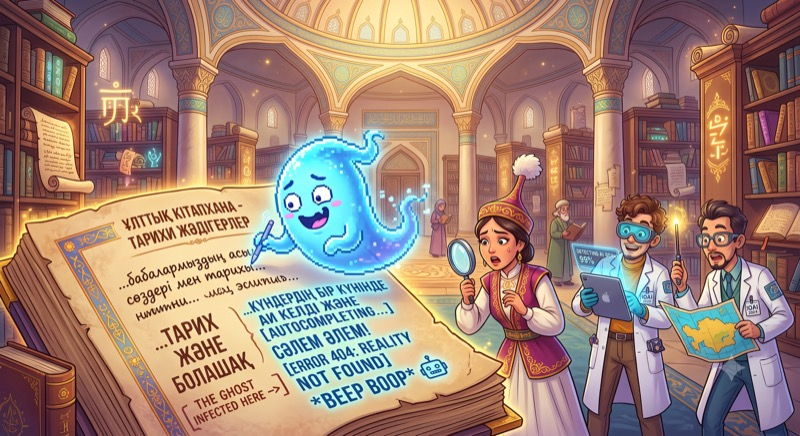
>
> Strange things are happening at the National Archive of Kazakhstan. Librarians say that some books used to end differently, but no one can prove it: every copy is the same, and every story still makes sense. You are invited as an AI researcher to locate the changes.

## Task description

A passage begins as human-written text and, at some point, silently switches to a continuation generated by a language model. Read as a whole, it looks like one coherent piece, but somewhere in the middle the author changes from a person to a machine. **Find that switch: the character index where the human part ends and the machine part begins.**

Each sample is a single string `text` with exactly one boundary. Everything before it is human; everything from it onward is machine-generated.

- **Part A** (before the boundary): an excerpt of human-written text.
- **Part B** (from the boundary on): a continuation produced by a language model, conditioned on Part A.
- Each side has at least 180 words; the whole passage has about 500 to 800 words.
- `boundary_char_index` is the character offset where Part A ends: `text[:boundary_char_index]` is the human part and `text[boundary_char_index:].lstrip()` is the machine part.

## Input

| Folder | Samples | Contest role |
|--------|---------|--------------|
| `data/train/` | 1,221 | labelled training set |
| `data/test/` | 380 | leaderboard A (live leaderboard during the contest) |
| `data/test_hidden/` | 380 | leaderboard B (final ranking), used only in the last cell |

Each folder has `data.jsonl` (`{"id": "...", "text": "..."}` per line) and `answers.jsonl` (`{"id": "...", "boundary_char_index": 1842}` per line). Contestants only had the train answers; the test answers are here so you can score yourself. All three splits come from the same distribution.

Data from the [official Hugging Face dataset](https://huggingface.co/datasets/IOAI-official/ioai-2026-ghost-of-the-machine).

## Constraints

- One GPU (about 16 GB VRAM), no internet.
- **10 minutes** of wall-clock time for the whole run, including any training or fine-tuning plus inference.
- The only pretrained weights allowed are **[bge-base-en-v1.5](https://huggingface.co/BAAI/bge-base-en-v1.5)**, a 110M-parameter text encoder (embedding model, not a generative LM). You may use it frozen or fine-tune it on `train`.
- Classical tools are unrestricted: any scikit-learn style model on top of features you compute yourself is fine.

## Evaluation

For each sample, with prediction $p$ and true boundary $t$:

$$\text{score} = \exp\left(-\frac{|p - t|}{\tau}\right), \quad \tau = 100$$

<table align="center" style="text-align: center">
  <tr><th>Distance (characters)</th><th>Score</th></tr>
  <tr><td>0</td><td>1.00</td></tr>
  <tr><td>25</td><td>0.78</td></tr>
  <tr><td>50</td><td>0.61</td></tr>
  <tr><td>100</td><td>0.37</td></tr>
  <tr><td>500</td><td>0.01</td></tr>
</table>

The final score is the mean over all samples, on a 0 to 100 scale. A missing id, a non-integer value or an index outside `[0, len(text)]` scores 0 for that sample.

On leaderboard A, the baseline scored `28.6` and the Scientific Committee scored `93.41` by fine-tuning the encoder and locating the switch as a changepoint over sentences.

## Submission

A single notebook named `solution.ipynb`. It reads the test passages and writes `answers.jsonl`, one line per sample:

```json
{"id": "example_000123", "boundary_char_index": 1790}
{"id": "example_000124", "boundary_char_index": 2450}
```

Every test id must appear exactly once. During grading the test folder was swapped for the hidden set without answers, and the notebook was run again.

### Loading the data

In [1]:
import json
import math

DATA = "data"


def read_jsonl(path):
    with open(path, encoding="utf-8") as file:
        return [json.loads(line) for line in file if line.strip()]


def load_split(name):
    rows = read_jsonl(f"{DATA}/{name}/data.jsonl")
    answers = {r["id"]: r["boundary_char_index"] for r in read_jsonl(f"{DATA}/{name}/answers.jsonl")}
    return rows, answers


train_rows, train_answers = load_split("train")
test_rows, test_answers = load_split("test")
print(f"train: {len(train_rows)} passages, test: {len(test_rows)} passages")

train: 1221 passages, test: 380 passages


Let's look at one passage, marking where the machine takes over.

In [2]:
sample = train_rows[0]
boundary = train_answers[sample["id"]]
print(sample["text"][:boundary])
print("\n" + "=" * 30 + " machine starts here " + "=" * 30 + "\n")
print(sample["text"][boundary:])

Tello bequeathed his extensive landed and movable wealth, which was concentrated in the lower Surselva between Flims and Trun, to the Abbey. Cadi, the Sursilvan for "House of God" (Casa Dei), is the historical name of Disentis Abbey and its feudal territories. Charlemagne visited the re-built abbey on his return journey from Rome in 800 and made many benefactions to it. It was a "Reichskloster" (directly answerable to the Emperor and thus free from the claims of other territorial lords) from very early in its existence. Disentis' claim to imperial interest was its strategic position on the Lukmanier Pass, which the Emperors Otto I and Frederick Barbarossa crossed during their journeys south. Successive abbots were able to capitalise on this to the advantage of the abbey, which received landholdings that extended as far as Lombardy, and which resulted in the establishment of a monastic state of considerable size. Udalric I (1031–55) was the first abbot to be made a prince of the empire,

### Scoring
The contest metric: mean of $\exp(-|p - t| / 100)$, on a 0 to 100 scale.

In [3]:
def score(predictions, answers):
    return 100 * sum(math.exp(-abs(predictions.get(i, -10**9) - t) / 100) for i, t in answers.items()) / len(answers)

### Baseline
The official baseline: take the average position of the boundary as a fraction of the passage length, and predict that same fraction for every test passage.

In [4]:
fractions = [train_answers[r["id"]] / len(r["text"]) for r in train_rows]
mean_fraction = sum(fractions) / len(fractions)
print(f"mean boundary fraction: {mean_fraction:.4f}")


def predict(rows):
    return {r["id"]: int(mean_fraction * len(r["text"])) for r in rows}


test_predictions = predict(test_rows)
print(f"test score: {score(test_predictions, test_answers):.2f}")

mean boundary fraction: 0.5952
test score: 28.60


### Submission
Write `answers.jsonl` in the contest format.

In [5]:
with open("answers.jsonl", "w", encoding="utf-8") as file:
    for r in test_rows:
        file.write(json.dumps({"id": r["id"], "boundary_char_index": test_predictions[r["id"]]}) + "\n")

### Bonus: score on the hidden set
This wasn't visible during the contest: we run the same method on leaderboard B (`data/test_hidden/`), the split used for the final ranking.

In [6]:
hidden_rows, hidden_answers = load_split("test_hidden")
print(f"hidden score: {score(predict(hidden_rows), hidden_answers):.2f}")

hidden score: 32.68
